In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Partie 1 : le fichier des données financières

In [22]:
# en millions de dirhams (M MAD) /  source : rapports financiers annuels Managem, comptes consolidés IFRS

In [23]:
Business_plan= pd.DataFrame({
    "annee":          [2023,    2024,    2025],
    "CA":             [7507.6,  8859.4,  13693.6],
    "EBIT":           [1001.6,  1287.7,  3992.8],
    "DA":             [1397.0,  1368.9,  2012.4],
    "RN_Part_Grpe":   [514.4,   619.8,   3002.0],
    "EBT":            [623.0,   973.5,   3798.0],
    "impot":          [-13.8,   198.5,   389.1],
    "capex":          [2755.9,  7254.0,  5950.0],
    "var_BFR":        [-73.4,   -476.0,  507.0],
    "dette_fin":      [9595.6,  12399.5, 15323.5],
    "tresorerie":     [2740.5,  2589.1,  4390.3],
    "minoritaires":   [662.7,   730.9,   1051.3],}).set_index("annee")

Business_plan["RN_Part_Grpe"]=Business_plan["RN_Part_Grpe"]-Business_plan["impot"]-Business_plan["minoritaires"]
Business_plan 

,CA,EBIT,DA,RN_Part_Grpe,EBT,impot,capex,var_BFR,dette_fin,tresorerie,minoritaires
annee,,,,,,,,,,,
2023,7507.6,1001.6,1397.0,-134.5,623.0,-13.8,2755.9,-73.4,9595.6,2740.5,662.7
2024,8859.4,1287.7,1368.9,-309.6,973.5,198.5,7254.0,-476.0,12399.5,2589.1,730.9
2025,13693.6,3992.8,2012.4,1561.6,3798.0,389.1,5950.0,507.0,15323.5,4390.3,1051.3


In [24]:
bsplan = pd.DataFrame({
    "annee":                [2023,    2024,    2025],
    "CA":                    [7507.6,  8859.4,  13693.6],
    "DA":                    [1397.0,  1368.9,  2012.4],  
    "EBIT":                  [1001.6,  1287.7,  3992.8],   # résultat des activités opérationnelles
    "resultat_financier":    [-378.6,  -314.3,  -194.7],
    "impot":                 [-13.8,   198.5,   389.1],    # impôts sur les bénéfices + impôts différés (charge)
    "mise_en_equivalence":   [-95.8,   12.5,    61.4],
    "minoritaires_resultat": [26.6,    167.6,   468.4],    # part des minoritaires dans le résultat
     "dette_non_courante":   [6832.1, 7951.6, 10544.2],
    "derives_non_courants": [244.7,  560.7,  1707.9],
    "dette_courante":       [3010.0, 5028.3, 6487.2],
    "derives_courants":     [1.8,    19.7,   0.0],
    "tresorerie":           [2740.5, 2589.1, 4390.3],
    "minoritaires":         [662.7,  730.9,  1051.3],
     "capex":                [2755.9, 7254.0, 5950.0],    # acquisitions d'immobilisations
    "var_BFR":               [-73.4, -476.0, 507.0],
    "capitaux_propres":     [8227.7, 11418.7, 12529.6]          
}).set_index("annee")

bsplan["EBITDA"] = bsplan["EBIT"] + bsplan["DA"]
bsplan["EBT"] = bsplan["EBIT"] + bsplan["resultat_financier"]
bsplan["R.net"] = bsplan["EBT"] - bsplan["impot"] + bsplan["mise_en_equivalence"]
bsplan["RN.PartGrp"] = bsplan["R.net"] - bsplan["minoritaires_resultat"]
bsplan["dette_nette"] = bsplan["dette_non_courante"]+bsplan["dette_courante"]-bsplan["derives_non_courants"]-bsplan["derives_courants"] - bsplan["tresorerie"]
# on remet les colonnes dans l'ordre du compte de résultat

bsplan = bsplan[["CA", "EBITDA", "DA", "EBIT", "resultat_financier", "EBT", "impot",
         "mise_en_equivalence", "R.net", "minoritaires_resultat", "RN.PartGrp","dette_nette","capex","var_BFR" ]]

bsplan





,CA,EBITDA,DA,EBIT,resultat_financier,EBT,impot,mise_en_equivalence,R.net,minoritaires_resultat,RN.PartGrp,dette_nette,capex,var_BFR
annee,,,,,,,,,,,,,,
2023,7507.6,2398.6,1397.0,1001.6,-378.6,623.0,-13.8,-95.8,541.0,26.6,514.4,6855.1,2755.9,-73.4
2024,8859.4,2656.6,1368.9,1287.7,-314.3,973.4,198.5,12.5,787.4,167.6,619.8,9810.4,7254.0,-476.0
2025,13693.6,6005.2,2012.4,3992.8,-194.7,3798.1,389.1,61.4,3470.4,468.4,3002.0,10933.2,5950.0,507.0


In [25]:
nb_actions = 118_646_760          # après la division par dix du 27 juillet 2026
cours = 1469                 
capitalisation = cours * nb_actions / 1e6     #1e6 convertit  en millions de MAD     

In [26]:
f = bsplan.copy()
f["croissance_CA"] = f["CA"].pct_change()
f["marge_EBITDA"] = f["EBITDA"] / f["CA"]
f["marge_EBIT"] = f["EBIT"] / f["CA"]
f["taux_IS"] = f["impot"] / f["EBT"]
f["capex_CA"] = f["capex"] / f["CA"]

# free cash flow pour l'entreprise (FCFF) : l'argent disponible pour les actionnaires ET les prêteurs
f["FCFF"] = f["EBIT"] * (1 - f["taux_IS"]) + f["DA"] - f["capex"] - f["var_BFR"]

f["levier"] = bsplan["dette_nette"] / bsplan["EBITDA"]      # dette nette / EBITDA

f.round(3).T

annee,2023,2024,2025
CA,7507.600,8859.400,13693.600
EBITDA,2398.600,2656.600,6005.200
DA,1397.000,1368.900,2012.400
EBIT,1001.600,1287.700,3992.800
resultat_financier,-378.600,-314.300,-194.700
EBT,623.000,973.400,3798.100
impot,-13.800,198.500,389.100
mise_en_equivalence,-95.800,12.500,61.400
R.net,541.000,787.400,3470.400
minoritaires_resultat,26.600,167.600,468.400


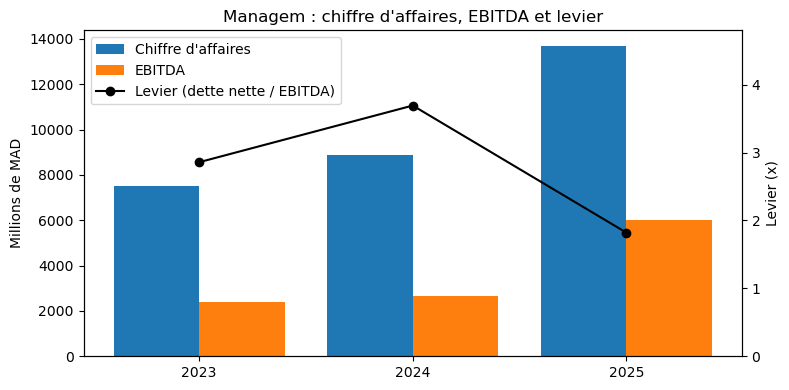

In [27]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(f.index - 0.2, f["CA"], width=0.4, label="Chiffre d'affaires")
ax.bar(f.index + 0.2, f["EBITDA"], width=0.4, label="EBITDA")
ax.set_xticks(f.index)
ax.set_title("Managem : chiffre d'affaires, EBITDA et levier")
ax.set_ylabel("Millions de MAD")

ax2 = ax.twinx()                                   # deuxième axe, à droite
ax2.plot(f.index, f["levier"], color="black", marker="o", label="Levier (dette nette / EBITDA)")
ax2.set_ylabel("Levier (x)")
ax2.set_ylim(0, f["levier"].max() * 1.3)

h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left")

plt.tight_layout()
plt.show()

 1- Entre 2024 et 2025, la marge d’EBITDA a fortement progressé, de 30 % à 44 %, et le levier a été divisé par deux, de 3,7x à 1,8x. Deux effets se combinent : l’entrée en production de Boto (or) et de Tizert (cuivre) au quatrième trimestre 2025, et la hausse des prix de l’or, de l’argent et du cuivre. Comme une grande partie des coûts d’une mine sont fixes, la hausse des prix se retrouve presque entièrement dans l’EBITDA : c’est le levier opérationnel. La dette nette a pourtant continué d’augmenter, de 9,8 à 10,9 milliards de dirhams, mais l’EBITDA a plus que doublé, d’où la forte baisse du levier. En 2024, au contraire, le levier avait atteint 3,7x : la dette finançait la construction des mines, qui ne produisaient pas encore
2- Oui, le FCFF de 2024 est très négatif, à −4,4 milliards de dirhams, à cause d’investissements record de 7,3 milliards pour construire Boto et Tizert. Ce n’est pas inquiétant en soi : c’est le profil normal d’une entreprise minière en phase de développement, qui investit plusieurs années avant de produire. Ce qui compte, c’est que ces investissements soient financés sans fragiliser l’entreprise : Managem a combiné une augmentation de capital d’environ 3 milliards et de nouveaux emprunts. Le FCFF reste encore légèrement négatif en 2025, car les mines n’ont produit que quelques mois. Il devrait devenir nettement positif en 2026, première année pleine de production : on le voit déjà au premier semestre 2026, avec un EBITDA de 6,2 milliards et des investissements retombés à 1,7 milliard
3- Non, ce serait risqué. Doubler le S1 2026 donnerait un chiffre d’affaires d’environ 23,5 milliards et un EBITDA d’environ 12,4 milliards, mais plusieurs raisons invitent à la prudence. D’abord, Managem annonce elle-même que le second semestre sera une “étape de consolidation”. Ensuite, la production a déjà baissé au premier semestre à Imiter (argent) et à Tri-K (or), à cause de difficultés opérationnelles. Enfin, la marge de 53 % dépend des prix très élevés des métaux, qui peuvent baisser à tout moment. Pour une entreprise cyclique, un semestre exceptionnel ne se prolonge pas mécaniquement : il vaut mieux construire plusieurs scénarios de prix et de volumes

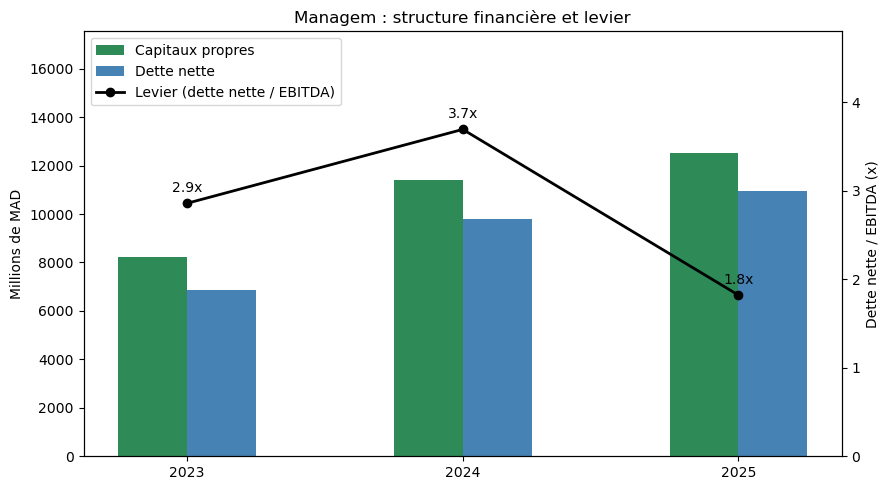

In [28]:
f["capitaux_propres"] = [8227.7, 11418.7, 12529.6]
x = np.arange(len(f.index))      # positions 0, 1, 2 pour les 3 années
largeur = 0.25

fig, ax = plt.subplots(figsize=(9, 5))

# les montants, en barres
ax.bar(x - largeur/2 ,f["capitaux_propres"], largeur, label="Capitaux propres", color="seagreen")
ax.bar(x + largeur/2 ,f["dette_nette"],      largeur, label="Dette nette", color="steelblue")
ax.set_xticks(x)
ax.set_xticklabels(f.index)
ax.set_ylabel("Millions de MAD")
ax.set_ylim(0, f[["capitaux_propres", "dette_nette"]].max().max() * 1.4)
ax.set_title("Managem : structure financière et levier")

# le levier, en courbe sur un deuxième axe
ax2 = ax.twinx()
ax2.plot(x, f["levier"], color="black", marker="o", lw=2, label="Levier (dette nette / EBITDA)")
for xi, v in zip(x, f["levier"]):
    ax2.annotate(f"{v:.1f}x", (xi, v), textcoords="offset points", xytext=(0, 8), ha="center")
ax2.set_ylabel("Dette nette / EBITDA (x)")
ax2.set_ylim(0, f["levier"].max() * 1.3)

# une seule légende pour les deux axes
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left")

plt.tight_layout()
plt.show()

# Partie 2: Valorisation par Multiples Boursiers 

In [29]:
# L'idée est simple : si des entreprises semblables valent en moyenne 6 fois leur EBITDA, Managem devrait valoir à peu près 6 fois le sien. C'est la méthode la plus utilisée en pratique, car elle reflète ce que le marché paie aujourd'hui.

In [30]:
import yfinance as yf

comparables = {
    "Endeavour Mining": "EDV.L",   # Or, Afrique de l'Ouest
    "Perseus Mining":   "PRU.AX",  # Or, Afrique de l'Ouest
    "B2Gold":           "BTG",     # Or, Afrique et Amériques
    "IAMGOLD":          "IAG",     # Or, ancien propriétaire de Boto
    "Fresnillo":        "FRES.L",  # argent et Or
    "Lundin Mining":    "LUN.TO",  # cuivre
    "Boliden":          "BOL.ST", }  # cuivre et zinc 
lignes = []                             #crée liste vide 
for nom, ticker in comparables.items():
    info = yf.Ticker(ticker).info
    lignes.append({"Société": nom,
                   "VE/EBITDA": info.get("enterpriseToEbitda"),
                   "PER": info.get("trailingPE"),
                   "Devise": info.get("currency"), "Cours": info.get("currentPrice")})

multiples = pd.DataFrame(lignes).set_index("Société")
multiples

,VE/EBITDA,PER,Devise,Cours
Société,,,,
Endeavour Mining,3.500,16.403162,GBp,4150.000
Perseus Mining,9.711,14.106383,AUD,6.630
B2Gold,3.319,6.396341,USD,5.245
IAMGOLD,4.724,8.164445,USD,18.370
Fresnillo,4.293,10.852814,GBp,2507.000
Lundin Mining,11.666,13.016806,CAD,30.980
Boliden,5.708,10.396020,SEK,522.400


In [34]:
#mutiple médian 
VE_EBITDA_median = multiples["VE/EBITDA"].median()
PER_median = multiples["PER"].median()

#parameter de Mangem 
EBITDA_2025 = f.loc[2025, "EBITDA"]
RN_PartGrp_2025 = f.loc[2025, "RN.PartGrp"]
dette_nette = f.loc[2025, "dette_nette"] 
minoritaires = f.loc[2025, "minoritaires_resultat"]

# méthode VE/EBITDA
VE_MNG_1 = VE_EBITDA_median * EBITDA_2025
Valeur_actions_MNG = VE_MNG_1 - dette_nette - minoritaires 
prix_Action_MNG= Valeur_actions_MNG * 1e6 / nb_actions

# méthode PER
EqV_MNG_2= PER_median * RN_PartGrp_2025
VE_MNG_2=EqV_MNG_2+dette_nette
prix_per = PER_median * RN_PartGrp_2025 * 1e6 / nb_actions

print(f"Prix par action, VE/EBITDA : {prix_Action_MNG:,.0f} MAD")
print(f"Prix par action, PER       : {prix_per:,.0f} MAD")
print(f"Cours actuel               : {cours:,.0f} MAD")
print (f"EV/EBITDA de Mangemn , VE/EBITDA : {VE_MNG_1/EBITDA_2025:,.0f}")

Prix par action, VE/EBITDA : 143 MAD
Prix par action, PER       : 275 MAD
Cours actuel               : 1,469 MAD
EV/EBITDA de Mangemn , VE/EBITDA : 5


# Partie 2 : DCF 

In [32]:
#calcul WACC 

In [35]:

rf = 0.0378            # bons du Trésor marocains à 10 ans
risk_premium = 0.042  # prime de marché mature (Damodaran)
kD = 0.0673            # coût de la dette avant impôt
t = 0.02             # taux d'impôt (effectif ou légal)



#calcul beta : 
mng = pd.read_csv("MNG.csv", sep=";", index_col=0, parse_dates=True, dayfirst=True).sort_index()
masi = pd.read_csv("MASI.csv", sep=";", index_col=0, parse_dates=True, dayfirst=True).sort_index()
def en_nombre(serie):
    """Transforme un texte comme '18 624,84' en nombre 18624.84."""
    s = serie.astype(str).str.replace("\u202f", "").str.replace("\xa0", "").str.replace(" ", "")
    s = s.str.replace(",", ".")
    return pd.to_numeric(s, errors="coerce")

cours_mng = en_nombre(mng["Dernier Cours"])
cours_masi = en_nombre(masi["Valeur indice"])

donnees = pd.concat([cours_mng, cours_masi], axis=1, join="inner", keys=["MNG", "MASI"])
donnees = donnees.resample("W").last()

rend = donnees.pct_change().dropna()
beta = rend.cov().loc["MNG", "MASI"] / rend["MASI"].var()
print(f"Bêta de Managem : {beta:.2f}  (sur {len(rend)} semaines)")
print(mng["Dernier Cours"].tail())
 
#Caclul KE et WACC
kE = rf + beta * (risk_premium )
E = capitalisation
D = dette_nette
WACC = E / (E + D) * kE + D / (E + D) * kD * (1 - t)

print(f"Coût des fonds propres : {kE:.2%}")
print(f"WACC : {WACC:.2%}")

Bêta de Managem : 1.72  (sur 52 semaines)
Séance
2026-11-03    1370.00
2026-11-04    1440.00
2026-11-05    1489.00
2026-11-09    1490.00
2026-11-10    1470.00
Name: Dernier Cours, dtype: object
Coût des fonds propres : 11.02%
WACC : 10.76%


In [36]:
# ---------- 1. TES HYPOTHÈSES ----------
croissance_CA = [0.60, 0.05, 0.03, 0.02, 0.02]   
capex_2026 = 0.15                                
t = 0.20                                         
g = 0.03                                          

# ---------- 2. LES RATIOS, TIRÉS DE 2025 ----------
marge_EBITDA = f.loc[2025, "EBITDA"] / f.loc[2025, "CA"]     # ≈ 43,9 %
taux_DA = f.loc[2025, "DA"] / f.loc[2025, "CA"]              # ≈ 14,7 %
BFR_2025 = 2774.8 + 2554.8 - 2266.1                          # stocks + créances clients - fournisseurs (bilan 2025)
taux_BFR = BFR_2025 / f.loc[2025, "CA"]                      # ≈ 22,4 %

hyp = croissance_CA        # nom utilisé dans les parties 7 et 8

In [37]:
def prevision(croissance_CA, t=0.20, choc_prix=0.0):
#Le forecasting : tout part du CA
    annees = list(range(2026, 2026 + len(croissance_CA)))
    prev = pd.DataFrame(index=annees)

    prev["croissance_CA"] = croissance_CA
    CA_volume = f.loc[2025, "CA"] * (1 + prev["croissance_CA"]).cumprod()
    prev["CA"] = CA_volume * (1 + choc_prix)
    prev["EBITDA"] = CA_volume * marge_EBITDA + CA_volume * choc_prix
    prev["DA"] = CA_volume * taux_DA
    prev["EBIT"] = prev["EBITDA"] - prev["DA"]
    prev["impot"] = prev["EBIT"] * t

    prev["capex"] = prev["DA"]                                        # capex = D&A…
    prev.loc[annees[0], "capex"] = CA_volume.iloc[0] * capex_2026     # …sauf la première année

    prev["BFR"] = prev["CA"] * taux_BFR
    prev["var_BFR"] = prev["BFR"].diff()                              # hausse du BFR
    prev.loc[annees[0], "var_BFR"] = prev.loc[annees[0], "BFR"] - BFR_2025

    prev["FCFF"] = prev["EBIT"] - prev["impot"] + prev["DA"] - prev["capex"] - prev["var_BFR"]
    return prev
prev = prevision(croissance_CA, t)
prev.round(0)



,croissance_CA,CA,EBITDA,DA,EBIT,impot,capex,BFR,var_BFR,FCFF
2026,1.0,21910.0,9608.0,3220.0,6388.0,1278.0,3286.0,4902.0,1838.0,3206.0
2027,0.0,23005.0,10089.0,3381.0,6708.0,1342.0,3381.0,5147.0,245.0,5121.0
2028,0.0,23695.0,10391.0,3482.0,6909.0,1382.0,3482.0,5301.0,154.0,5373.0
2029,0.0,24169.0,10599.0,3552.0,7047.0,1409.0,3552.0,5407.0,106.0,5532.0
2030,0.0,24653.0,10811.0,3623.0,7188.0,1438.0,3623.0,5515.0,108.0,5642.0


In [54]:
def dcf(croissance_CA, WACC, g, t=0.20, choc_prix=0.0, afficher=False):
   
    prev = prevision(croissance_CA, t, choc_prix)
    prev["facteur_actu"] = 1 / (1 + WACC) ** np.arange(1, len(prev) + 1)
    prev["FCFF_actu"] = prev["FCFF"] * prev["facteur_actu"]

    VT = prev["FCFF"].iloc[-1] * (1 + g) / (WACC - g)          # valeur terminale (Gordon-Shapiro)
    VT_actu = VT * prev["facteur_actu"].iloc[-1]
    VE = prev["FCFF_actu"].sum() + VT_actu

    if afficher:
        actions = VE - dette_nette - minoritaires 
        print(prev.round(0).T)
        print(f"\nSomme des FCFF actualisés    : {prev['FCFF_actu'].sum():>10,.0f} M MAD")
        print(f"Valeur terminale (en {prev.index[-1]})  : {VT:>10,.0f} M MAD")
        print(f"Valeur terminale actualisée  : {VT_actu:>10,.0f} M MAD  ({VT_actu / VE:.0%} de la VE)")
        print(f"Valeur d'entreprise          : {VE:>10,.0f} M MAD")
        print(f"- dette nette                : {-dette_nette:>10,.0f}")
        print(f"= valeur des actions         : {actions:>10,.0f} M MAD")
        print(f"Prix par action              : {actions * 1e6 / nb_actions:>10,.0f} MAD")
    return prev, VE, VT_actu


def prix_action(VE):
    return (VE - dette_nette - minoritaires ) * 1e6 / nb_actions
    
projection, VE, VT_actu = dcf(croissance_CA, WACC, g, t, afficher=True)

                  2026     2027     2028     2029     2030
croissance_CA      1.0      0.0      0.0      0.0      0.0
CA             21910.0  23005.0  23695.0  24169.0  24653.0
EBITDA          9608.0  10089.0  10391.0  10599.0  10811.0
DA              3220.0   3381.0   3482.0   3552.0   3623.0
EBIT            6388.0   6708.0   6909.0   7047.0   7188.0
impot           1278.0   1342.0   1382.0   1409.0   1438.0
capex           3286.0   3381.0   3482.0   3552.0   3623.0
BFR             4902.0   5147.0   5301.0   5407.0   5515.0
var_BFR         1838.0    245.0    154.0    106.0    108.0
FCFF            3206.0   5121.0   5373.0   5532.0   5642.0
facteur_actu       1.0      1.0      1.0      1.0      1.0
FCFF_actu       2895.0   4174.0   3954.0   3676.0   3385.0

Somme des FCFF actualisés    :     18,083 M MAD
Valeur terminale (en 2030)  :     74,881 M MAD
Valeur terminale actualisée  :     44,919 M MAD  (71% de la VE)
Valeur d'entreprise          :     63,002 M MAD
- dette nette            

In [55]:
# Pessimiste : S2 2026 en baisse, puis recul du CA
prix_pessimiste= dcf([0.55, -0.05, 0.00, 0.02, 0.02], WACC, g, t, afficher=True)
projection, VE, VT_actu = dcf([0.55, -0.05, 0.00, 0.02, 0.02], WACC, g, t, afficher=True)


                  2026     2027     2028     2029     2030
croissance_CA      1.0     -0.0      0.0      0.0      0.0
CA             21225.0  20164.0  20164.0  20567.0  20978.0
EBITDA          9308.0   8843.0   8843.0   9020.0   9200.0
DA              3119.0   2963.0   2963.0   3023.0   3083.0
EBIT            6189.0   5879.0   5879.0   5997.0   6117.0
impot           1238.0   1176.0   1176.0   1199.0   1223.0
capex           3184.0   2963.0   2963.0   3023.0   3083.0
BFR             4748.0   4511.0   4511.0   4601.0   4693.0
var_BFR         1685.0   -237.0      0.0     90.0     92.0
FCFF            3202.0   4941.0   4704.0   4707.0   4802.0
facteur_actu       1.0      1.0      1.0      1.0      1.0
FCFF_actu       2891.0   4027.0   3461.0   3128.0   2880.0

Somme des FCFF actualisés    :     16,387 M MAD
Valeur terminale (en 2030)  :     63,721 M MAD
Valeur terminale actualisée  :     38,224 M MAD  (70% de la VE)
Valeur d'entreprise          :     54,612 M MAD
- dette nette            

In [56]:
# Normal
prix_normal= dcf([0.63, 0.05, 0.03, 0.02, 0.02], WACC, g, t, afficher=True)
projection, VE, VT_actu = dcf([0.63, 0.05, 0.03, 0.02, 0.02], WACC, g, t, afficher=True)

                  2026     2027     2028     2029     2030
croissance_CA      1.0      0.0      0.0      0.0      0.0
CA             22321.0  23437.0  24140.0  24622.0  25115.0
EBITDA          9788.0  10278.0  10586.0  10798.0  11014.0
DA              3280.0   3444.0   3548.0   3619.0   3691.0
EBIT            6508.0   6834.0   7039.0   7179.0   7323.0
impot           1302.0   1367.0   1408.0   1436.0   1465.0
capex           3348.0   3444.0   3548.0   3619.0   3691.0
BFR             4994.0   5243.0   5400.0   5508.0   5619.0
var_BFR         1930.0    250.0    157.0    108.0    110.0
FCFF            3209.0   5217.0   5474.0   5636.0   5748.0
facteur_actu       1.0      1.0      1.0      1.0      1.0
FCFF_actu       2897.0   4253.0   4028.0   3744.0   3448.0

Somme des FCFF actualisés    :     18,371 M MAD
Valeur terminale (en 2030)  :     76,285 M MAD
Valeur terminale actualisée  :     45,761 M MAD  (71% de la VE)
Valeur d'entreprise          :     64,132 M MAD
- dette nette            

In [57]:
# Optimiste : S2 2026 égal au S1, puis croissance soutenue
prix_optimiste = dcf([0.72, 0.08, 0.05, 0.03, 0.02], WACC, g, t, afficher=True)
projection, VE, VT_actu = dcf([0.72, 0.08, 0.05, 0.03, 0.02], WACC, g, t, afficher=True)

                  2026     2027     2028     2029     2030
croissance_CA      1.0      0.0      0.0      0.0      0.0
CA             23553.0  25437.0  26709.0  27510.0  28061.0
EBITDA         10329.0  11155.0  11713.0  12064.0  12306.0
DA              3461.0   3738.0   3925.0   4043.0   4124.0
EBIT            6868.0   7417.0   7788.0   8022.0   8182.0
impot           1374.0   1483.0   1558.0   1604.0   1636.0
capex           3533.0   3738.0   3925.0   4043.0   4124.0
BFR             5269.0   5691.0   5975.0   6155.0   6278.0
var_BFR         2206.0    422.0    285.0    179.0    123.0
FCFF            3217.0   5512.0   5946.0   6238.0   6422.0
facteur_actu       1.0      1.0      1.0      1.0      1.0
FCFF_actu       2904.0   4493.0   4376.0   4145.0   3853.0

Somme des FCFF actualisés    :     19,770 M MAD
Valeur terminale (en 2030)  :     85,232 M MAD
Valeur terminale actualisée  :     51,129 M MAD  (72% de la VE)
Valeur d'entreprise          :     70,899 M MAD
- dette nette            

# Partie 3 : Le football field 

364.19205530715254 444.4310403404922 501.4645178659198
101 294 235 343


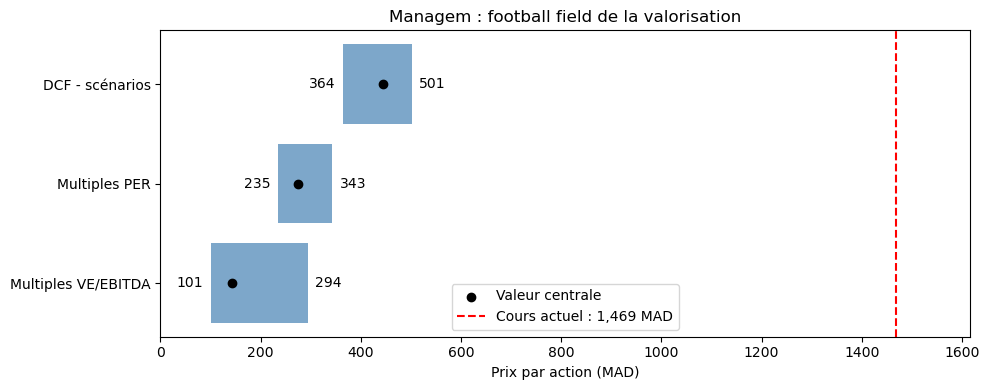

In [61]:
# fourchette des multiples (1er et 3e quartiles des comparables)
q1_e, q3_e = multiples["VE/EBITDA"].quantile([0.25, 0.75])
q1_p, q3_p = multiples["PER"].quantile([0.25, 0.75])

EBITDA_2025 = f.loc[2025, "EBITDA"]
RN_PartGrp_2025 = f.loc[2025, "RN.PartGrp"]

prix_ebitda_bas  = (q1_e * EBITDA_2025 - dette_nette - minoritaires ) * 1e6 / nb_actions
prix_ebitda_haut = (q3_e * EBITDA_2025 - dette_nette - minoritaires ) * 1e6 / nb_actions

prix_per_bas  = q1_p * RN_PartGrp_2025 * 1e6 / nb_actions
prix_per_haut = q3_p * RN_PartGrp_2025 * 1e6 / nb_actions

prix_pessimiste = prix_action(dcf([0.55, -0.05, 0.00, 0.02, 0.02], WACC, g, t)[1])
prix_normal     = prix_action(dcf([0.63,  0.05, 0.03, 0.02, 0.02], WACC, g, t)[1])
prix_optimiste  = prix_action(dcf([0.72,  0.08, 0.05, 0.03, 0.02], WACC, g, t)[1])

print(prix_pessimiste, prix_normal, prix_optimiste)     # trois nombres
print(round(prix_ebitda_bas), round(prix_ebitda_haut), round(prix_per_bas), round(prix_per_haut))
ff = pd.DataFrame({
    "Bas":     [prix_ebitda_bas, prix_per_bas, prix_pessimiste],
    "Central": [prix_Action_MNG,     prix_per,     prix_normal],
    "Haut":    [prix_ebitda_haut, prix_per_haut, prix_optimiste],
}, index=["Multiples VE/EBITDA", "Multiples PER", "DCF - scénarios"])

fig, ax = plt.subplots(figsize=(10, 4))
y = range(len(ff))
for i, (bas, haut) in enumerate(zip(ff["Bas"], ff["Haut"])):
    ax.text(bas - 15, i, f"{bas:,.0f}", ha="right", va="center")
    ax.text(haut + 15, i, f"{haut:,.0f}", ha="left", va="center")
ax.barh(y, ff["Haut"] - ff["Bas"], left=ff["Bas"], color="steelblue", alpha=0.7)
ax.scatter(ff["Central"], y, color="black", zorder=3, label="Valeur centrale")
ax.axvline(cours, color="red", ls="--", label=f"Cours actuel : {cours:,.0f} MAD")
ax.set_yticks(list(y))
ax.set_yticklabels(ff.index)
ax.set_xlabel("Prix par action (MAD)")
ax.set_title("Managem : football field de la valorisation")
ax.legend()
ax.set_xlim(0, cours * 1.1)
plt.tight_layout()
plt.show()
